# Reproduce "Combined clinical, metabolomic, and polygenic scores for cardiovascular risk prediction" by ESC

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


### If you want to add or remove data, please modify it in the “Download Data” section.


In [ ]:
# Download data
!dx download "UKBRISK_ENModels/Benchmarking/EN_CVD_clinicalrisk_survival_probs_combined_10y.csv"
!dx download "UKBRISK_ENModels/Benchmarking/EN_CVD_pmh_ts_survival_probs_combined_10y.csv"
!dx download "UKBRISK_ENModels/Benchmarking/EN_CVD_qrisk_survival_probs_combined_10y.csv"
!dx download "UKBRISK_ENModels/Benchmarking/EN_CVD_clinicalrisk_pmh_ts_survival_probs_combined_10y.csv"
!dx download "UKBRISK_ENModels/Benchmarking/EN_CVD_prs_metabolomics_pmh_ts_survival_probs_combined_10y.csv"
!dx download "UKBRISK_ENModels/Benchmarking/EN_CVD_clinicalrisk_prs_metabolomics_survival_probs_combined_10y.csv"
!dx download "UKBRISK_ENModels/Benchmarking/EN_CVD_everything_survival_probs_combined_10y.csv"

!dx download "UKBRISK_ENModels/NHC/Initial_10y/EN_CVD_nhc_pmh_ts_survival_probs_combined_10y.csv"
!dx download "UKBRISK_ENModels/NHC/Initial_10y/EN_CVD_nhc_prs_metabolomics_pmh_ts_survival_probs_combined_10y.csv"

!dx download "UKBRISK_ENModels/Benchmarking/EN_CVD_prevent_survival_probs_combined_10y.csv"
!dx download "UKBRISK_ENModels/Benchmarking/EN_CVD_score_survival_probs_combined_10y.csv"
!dx download "Andy/ageAtRecruitment.csv"
!dx download "Andy/to_eventCVD.csv"

Error: path
"/opt/notebooks/EN_CVD_clinicalrisk_survival_probs_combined_10y.csv" already
exists but -f/--overwrite was not set
Error: path "/opt/notebooks/EN_CVD_pmh_ts_survival_probs_combined_10y.csv"
already exists but -f/--overwrite was not set
Error: path "/opt/notebooks/EN_CVD_qrisk_survival_probs_combined_10y.csv"
already exists but -f/--overwrite was not set
Error: path
"/opt/notebooks/EN_CVD_clinicalrisk_pmh_ts_survival_probs_combined_10y.csv"
already exists but -f/--overwrite was not set
Error: path "/opt/notebooks/EN_CVD_prs_metabolomics_pmh_ts_survival_probs_comb
ined_10y.csv" already exists but -f/--overwrite was not set
Error: path "/opt/notebooks/EN_CVD_clinicalrisk_prs_metabolomics_survival_prob
s_combined_10y.csv" already exists but -f/--overwrite was not set
Error: path "/opt/notebooks/EN_CVD_everything_survival_probs_combined_10y.csv"
already exists but -f/--overwrite was not set
Error: path "/opt/notebooks/EN_CVD_nhc_pmh_ts_survival_probs_combined_10y.csv"
already ex

In [3]:
# Read data
clinicalrisk = pd.read_csv("EN_CVD_clinicalrisk_survival_probs_combined_10y.csv")
clinicalrisk_pmh_ts = pd.read_csv("EN_CVD_clinicalrisk_pmh_ts_survival_probs_combined_10y.csv")
everything = pd.read_csv("EN_CVD_everything_survival_probs_combined_10y.csv")
pmh_ts = pd.read_csv("EN_CVD_pmh_ts_survival_probs_combined_10y.csv")
pmh_ts_metabolomics_PRS = pd.read_csv("EN_CVD_prs_metabolomics_pmh_ts_survival_probs_combined_10y.csv")
clinicalrisk_prs_metabolomics = pd.read_csv("EN_CVD_clinicalrisk_prs_metabolomics_survival_probs_combined_10y.csv")

NHS_health_check = pd.read_csv("EN_CVD_nhc_pmh_ts_survival_probs_combined_10y.csv")
NHS_health_check_omics = pd.read_csv("EN_CVD_nhc_prs_metabolomics_pmh_ts_survival_probs_combined_10y.csv")

Qrisk = pd.read_csv("EN_CVD_qrisk_survival_probs_combined_10y.csv")
SCORE2 = pd.read_csv("EN_CVD_score_survival_probs_combined_10y.csv")
PREVENT = pd.read_csv("EN_CVD_prevent_survival_probs_combined_10y.csv")

age_eid = pd.read_csv("ageAtRecruitment.csv")
CVD_status = pd.read_csv("to_eventCVD.csv")

# Create a list for different models.
## 1. The dataframe name will determine the model name displayed in the figure.
## 2. The variable names must match those defined in the data reading section.


In [ ]:
datasets = {
    "Clinicalrisk": clinicalrisk,
    "Clinicalrisk + PMH + Questionnaires": clinicalrisk_pmh_ts,
    "Everything(Clinical Model + PMH + Questionnaires + Omics + PRS)": everything,
    "No Needle Model(PMH + questionnaires)": pmh_ts,
    "Single Blood Draw Model(PMH + questionnaires + metabolomics + PRS)": pmh_ts_metabolomics_PRS,
    "Clinicalrisk + PRS + Metabolomics": clinicalrisk_prs_metabolomics,
    "NHS Health Check (NHC + PMH + Questionnaires)": NHS_health_check,
    "NHS Health Check + Omics (NHC + PMH + Questionnaires + PRS + metabolomics)": NHS_health_check_omics,
    "Qrisk": Qrisk,
    "SCORE2": SCORE2,
    "PREVENT": PREVENT
}

In [ ]:
# Automatically extract the test set and add "_test" to the variable names
for name,df in datasets.items():
    globals()[name + "_test"] = df[df["set"] == "test"]

In [ ]:
# Automatically extract the test set and calculate the 10-year risk percentage
datasets_test = {
    name: df[df["set"] == "test"].copy()
    for name, df in datasets.items()
}
for name,df in datasets_test.items():
    df["risk_percentage"] = 1 - df["survival_probability"]

In [ ]:
# Merge age at recruitment and CVD status into the dataset
for name,df in datasets_test.items():
    df = df.merge(age_eid[["Age.at.recruitment", "eid"]], on = "eid", how = "left")
    df = df.merge(CVD_status[["eid", "CVD_followup", "CVD_status"]], on = "eid", how = "left")
    datasets_test[name] = df

In [8]:
# Stratify data
stratification = [
    "low", "medium", "high",
    "low", "medium", "high"
]
for name,df in datasets_test.items():
    condition = [
    ((df["Age.at.recruitment"] < 50) & (df["risk_percentage"] < 0.025)), 
    ((df["Age.at.recruitment"] < 50) & (df["risk_percentage"] >= 0.025) & (df["risk_percentage"] < 0.075)),
    ((df["Age.at.recruitment"] < 50) & (df["risk_percentage"] >= 0.075)),
    
    ((df["Age.at.recruitment"] >= 50) & (df["risk_percentage"] < 0.05)), 
    ((df["Age.at.recruitment"] >= 50) & (df["risk_percentage"] >= 0.05) & (df["risk_percentage"] < 0.1)),
    ((df["Age.at.recruitment"] >= 50) & (df["risk_percentage"] > 0.1))
]
    
    df["risk_stratification"] = np.select(condition, stratification)

In [ ]:
# Calculate the number of low-, medium-, and high-risk individuals
datasets_test_amount = pd.DataFrame(columns = ["model", "low", "medium", "high"])
for name,df in datasets_test.items():
    counts = df["risk_stratification"].value_counts()

    datasets_test_amount.loc[len(datasets_test_amount)] = {
        "model": name,
        "low": counts.get("low", 0),
        "medium": counts.get("medium", 0),
        "high": counts.get("high", 0)
    }


In [10]:
qrisk_row = datasets_test_amount[datasets_test_amount["model"] == "Qrisk"]
other_rows = datasets_test_amount[datasets_test_amount["model"] != "Qrisk"]

datasets_test_amount = pd.concat([qrisk_row, other_rows], ignore_index=True)

In [ ]:
# If you want to rerun datasets_test_amount run the code down here
# Delete data
# datasets_test_amount = datasets_test_amount.iloc[0:0]
# datasets_test_amount

In [12]:
# Create Dataframe for figure
figure = pd.DataFrame(columns = ["model", "high_risk_delta", "CVD_high_risk_delta", "CVD_prevented_delta", "NNS_delta", "NNT_delta"])
absolute_figure = pd.DataFrame(columns = ["model", "high_risk", "CVD_high_risk", "CVD_prevented", "NNS", "NNT"])
figure["model"] = datasets_test_amount["model"]
absolute_figure["model"] = datasets_test_amount["model"]

In [13]:
# Calculate high risk absolute/delta 
Qrisk_high = datasets_test_amount.loc[0, "high"]
figure["high_risk_delta"] = datasets_test_amount["high"].sub(Qrisk_high)

absolute_figure["high_risk"] = datasets_test_amount["high"].copy()

In [14]:
# Calaulate CVD high risk absolute/delta
CVD_high_risk = pd.DataFrame(columns = ["model", "delta"])

high_counts = {}

for name, df in datasets_test.items():
    count = ((df["risk_stratification"] == "high") & 
             (df["CVD_status"] == True)).sum()
    high_counts[name] = count
    
qrisk_count = high_counts["Qrisk"]

for name, count in high_counts.items():
    figure.loc[figure["model"] == name, "CVD_high_risk_delta"] = count - qrisk_count
    absolute_figure.loc[absolute_figure["model"] == name, "CVD_high_risk"] = count
    

In [15]:
# Calculate prevented CVD events absolute/delta
from decimal import Decimal, ROUND_HALF_UP
figure["CVD_prevented_delta"] = figure["CVD_high_risk_delta"] * 0.2
# figure["CVD_prevented_delta"] = np.round(figure["CVD_prevented_delta"]).astype(int)

absolute_figure["CVD_prevented"] = absolute_figure["CVD_high_risk"] * 0.2
# absolute_figure["CVD_prevented"] = np.round(absolute_figure["CVD_prevented"]).astype(int)


In [16]:
# Number needed to screen (NNS) absolute/delta
absolute_figure["NNS"] = len(datasets_test["Qrisk"]) / absolute_figure["CVD_prevented"]
Qrisk_NNS = absolute_figure.loc[0,"NNS"]

figure["NNS_delta"] = absolute_figure["NNS"] - Qrisk_NNS


In [17]:
# Number needed to treated (NNT) absolute/delta
absolute_figure["NNT"] = absolute_figure["high_risk"]/absolute_figure["CVD_prevented"]
Qrisk_NNT = absolute_figure.loc[0, "NNT"]
figure["NNT_delta"] = absolute_figure["NNT"] - Qrisk_NNT


In [18]:
# Merge absolute and delta into one DF
plot = absolute_figure.merge(figure, on = "model", how = "left")

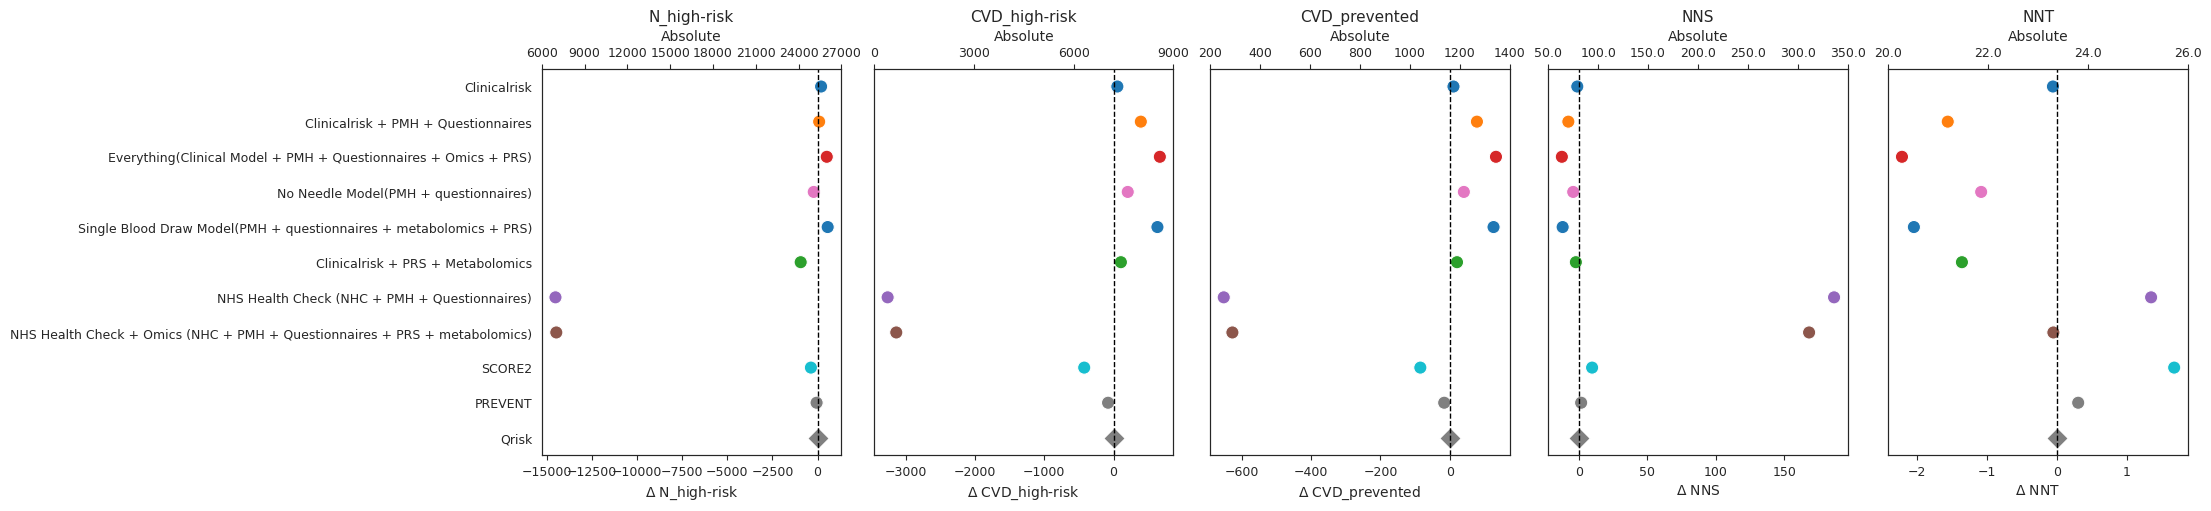

In [19]:
# Create plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Global color mapping
all_models = sorted(figure["model"].unique())

palette = dict(zip(
    all_models,
    sns.color_palette("tab10", len(all_models))
))

# baseline model
baseline_model = "Qrisk"
plot_no_base = plot[plot["model"] != baseline_model].copy()

metrics = ["high_risk", "CVD_high_risk", "CVD_prevented", "NNS", "NNT"]

baseline_df = plot[plot["model"] == baseline_model].copy()
for metric in metrics:
    baseline_df[f"{metric}_delta"] = 0

# unique models（
models = plot_no_base["model"].unique()


# title
title_map = {
    "high_risk": "N_high-risk",
    "CVD_high_risk": "CVD_high-risk",
    "CVD_prevented": "CVD_prevented",
    "NNS": "NNS",
    "NNT": "NNT"
}

# find baseline row
baseline_row = plot.loc[plot["model"] == baseline_model].iloc[0]

# Plot style
sns.set_style("white")
fig, axes = plt.subplots(1, len(metrics), figsize=(22, 5), constrained_layout=True)

# Loop for plots
for i, (ax, metric) in enumerate(zip(axes, metrics)):
    delta_col = f"{metric}_delta"

    # scatterplot
    sns.scatterplot(
        data=plot_no_base,
        x=delta_col,
        y="model",
        hue="model",
        ax=ax,
        palette = palette,
        s=90,
        legend=False
    )
    
    sns.scatterplot(
    data=baseline_df,
    x=delta_col,
    y="model",
    ax=ax,
    color="grey",
    s=120,
    marker="D",
    legend=False
    )

    # 0 line
    ax.axvline(0, color="black", linewidth=1, linestyle = "--")

    # panel title
    ax.set_title(title_map[metric], fontsize=11)

    # bottom x title：delta
    ax.set_xlabel(r"$\Delta$ " + title_map[metric], fontsize=10)
    ax.set_ylabel("")

    # top x absolute title
    ax_top = ax.twiny()

    baseline = baseline_row[metric]

    # delta range
    xmin, xmax = ax.get_xlim()

    # transfer to absolute range
    abs_min = xmin + baseline
    abs_max = xmax + baseline

    # step
    step = 2

    # setting step
    abs_range = abs_max - abs_min
    if abs_range > 20:
        step = 10
    if abs_range > 100:
        step = 50
    if abs_range > 300:
        step = 200
    if abs_range > 1000:
        step = 1000
    if abs_range > 2000:
        step = 3000

    # create absolute ticks
    abs_ticks = np.arange(
        np.floor(abs_min / step) * step,
        np.ceil(abs_max / step) * step + step,
        step
    )


    delta_ticks = abs_ticks - baseline

    ax_top.set_xlim(ax.get_xlim())
    ax_top.set_xticks(delta_ticks)

    if metric in ["NNS", "NNT"]:
        ax_top.set_xticklabels([f"{t:.1f}" for t in abs_ticks], fontsize=9)
    else:
        ax_top.set_xticklabels([f"{t:.0f}" for t in abs_ticks], fontsize=9)

    ax_top.set_xlabel("Absolute", fontsize=10)

    ax.tick_params(axis="x", labelsize=9)
    ax.tick_params(axis="y", labelsize=9)
    
    # delete other y axis name
    if i != 0:
        ax.set_yticklabels([])
        ax.set_yticks([])
    
    ax.grid(False)
    ax_top.grid(False)

plt.show()

# Target screening (use No Needle model as 1st step, other models as 2nd step)

In [20]:
target_screening = {}
for model_name, model_df in datasets_test.items():
    # use pmh_ts as 1st step
    new_df = datasets_test["No Needle Model(PMH + questionnaires)"].copy()
    
    # create a temperate df for other model
    temp = model_df[["eid", "risk_stratification"]].rename(columns = {"risk_stratification": "model_risk"})
    
    # merge with 1st step
    new_df = new_df.merge(temp, on = "eid", how = "left")
    
    # find the medium risk in 1st step
    mask = new_df["risk_stratification"] == "medium"
    
    # change it to the new stratification
    new_df.loc[mask, "risk_stratification"] = new_df.loc[mask, "model_risk"]
    
    # drop the temperate column
    new_df = new_df.drop(columns=["model_risk"])
    
    # create new datasets
    target_screening[model_name] = new_df

In [21]:
# Calaulate the amount of low, medium and high
target_screening_amount = pd.DataFrame(columns = ["model", "low", "medium", "high"])
for name,df in target_screening.items():
    counts = df["risk_stratification"].value_counts()

    target_screening_amount.loc[len(target_screening_amount)] = {
        "model": name,
        "low": counts.get("low", 0),
        "medium": counts.get("medium", 0),
        "high": counts.get("high", 0)
    }


In [22]:
qrisk_row = target_screening_amount[target_screening_amount["model"] == "Qrisk"]
other_rows = target_screening_amount[target_screening_amount["model"] != "Qrisk"]

target_screening_amount = pd.concat([qrisk_row, other_rows], ignore_index=True)

In [23]:
# Create Dataframe for figure
target_figure = pd.DataFrame(columns = ["model", "high_risk_delta", "CVD_high_risk_delta", "CVD_prevented_delta", "NNS_delta", "NNT_delta"])
target_absolute_figure = pd.DataFrame(columns = ["model", "high_risk", "CVD_high_risk", "CVD_prevented", "NNS", "NNT"])
target_figure["model"] = target_screening_amount["model"]
target_absolute_figure["model"] = target_screening_amount["model"]

In [24]:
# Calculate high risk absolute/delta 
target_Qrisk_high = target_screening_amount.loc[0, "high"]
target_figure["high_risk_delta"] = target_screening_amount["high"].sub(target_Qrisk_high)

target_absolute_figure["high_risk"] = target_screening_amount["high"].copy()

In [25]:
# Calaulate CVD high risk absolute/delta
target_CVD_high_risk = pd.DataFrame(columns = ["model", "delta"])

target_high_counts = {}

for name, df in target_screening.items():
    target_count = ((df["risk_stratification"] == "high") & 
             (df["CVD_status"] == True)).sum()
    target_high_counts[name] = target_count
    
target_qrisk_count = target_high_counts["Qrisk"]

for name, target_count in target_high_counts.items():
    target_figure.loc[target_figure["model"] == name, "CVD_high_risk_delta"] = target_count - target_qrisk_count
    target_absolute_figure.loc[target_absolute_figure["model"] == name, "CVD_high_risk"] = target_count
    

In [26]:
# Calculate prevented CVD events absolute/delta
from decimal import Decimal, ROUND_HALF_UP
target_figure["CVD_prevented_delta"] = target_figure["CVD_high_risk_delta"] * 0.2
# figure["CVD_prevented_delta"] = np.round(figure["CVD_prevented_delta"]).astype(int)

target_absolute_figure["CVD_prevented"] = target_absolute_figure["CVD_high_risk"] * 0.2
# absolute_figure["CVD_prevented"] = np.round(absolute_figure["CVD_prevented"]).astype(int)


In [27]:
# Number needed to screen (NNS) absolute/delta
target_absolute_figure["NNS"] = len(target_screening["Qrisk"]) / target_absolute_figure["CVD_prevented"]
target_Qrisk_NNS = target_absolute_figure.loc[0,"NNS"]

target_figure["NNS_delta"] = target_absolute_figure["NNS"] - target_Qrisk_NNS

In [28]:
# Number needed to treated (NNT) absolute/delta
target_absolute_figure["NNT"] = target_absolute_figure["high_risk"]/target_absolute_figure["CVD_prevented"]
target_Qrisk_NNT = target_absolute_figure.loc[0, "NNT"]
target_figure["NNT_delta"] = target_absolute_figure["NNT"] - target_Qrisk_NNT

In [29]:
# Merge absolute and delta into one DF
target_plot = target_absolute_figure.merge(target_figure, on = "model", how = "left")

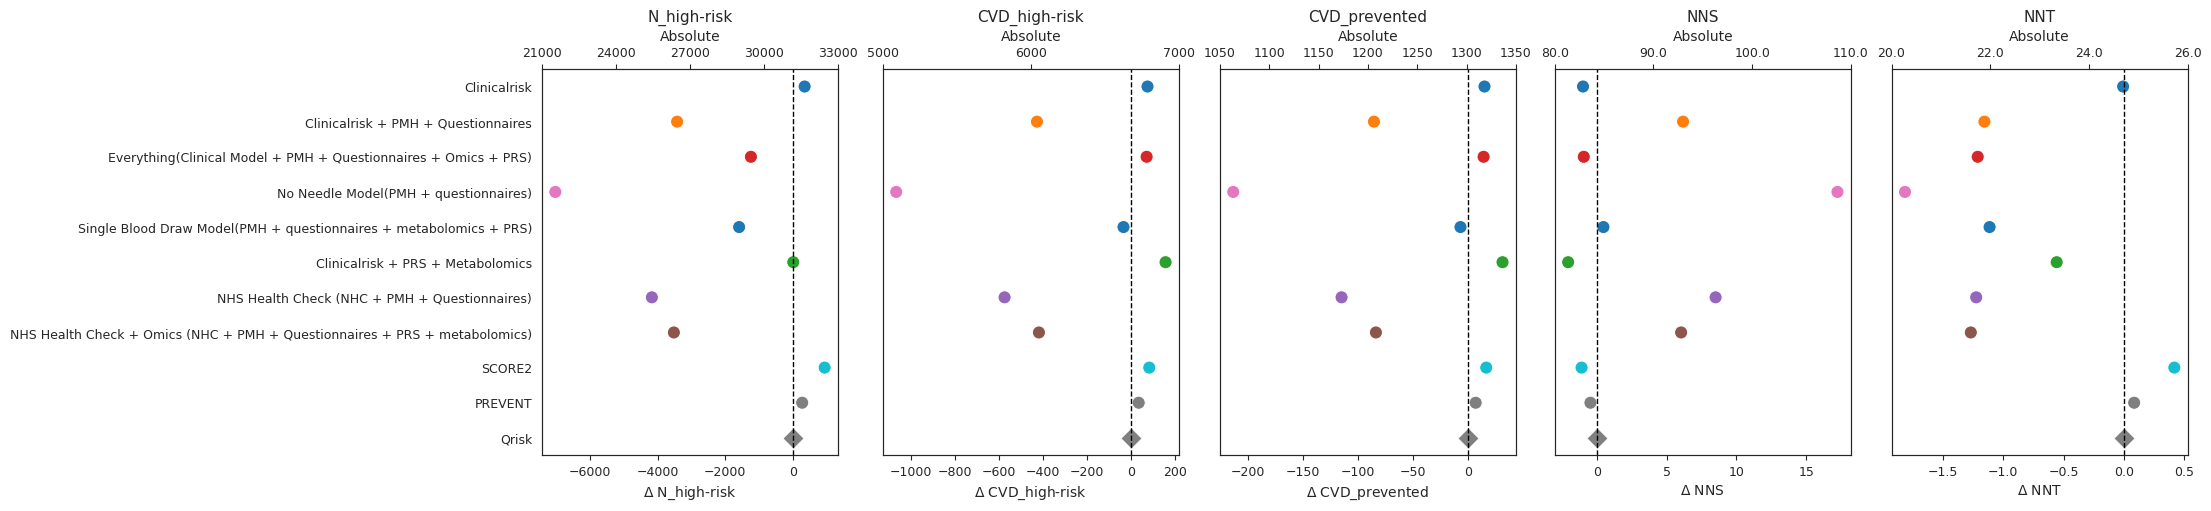

In [30]:
# Create plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# baseline model
target_baseline_model = "Qrisk"
target_plot_no_base = target_plot[target_plot["model"] != target_baseline_model].copy()

metrics = ["high_risk", "CVD_high_risk", "CVD_prevented", "NNS", "NNT"]

target_baseline_df = target_plot[target_plot["model"] == target_baseline_model].copy()
for metric in metrics:
    target_baseline_df[f"{metric}_delta"] = 0

# unique models（
target_models = target_plot_no_base["model"].unique()


# title
title_map = {
    "high_risk": "N_high-risk",
    "CVD_high_risk": "CVD_high-risk",
    "CVD_prevented": "CVD_prevented",
    "NNS": "NNS",
    "NNT": "NNT"
}

# find baseline row
target_baseline_row = target_plot.loc[target_plot["model"] == target_baseline_model].iloc[0]

# Plot style
sns.set_style("white")
fig, axes = plt.subplots(1, len(metrics), figsize=(22, 5), constrained_layout=True)

# Loop for plots
for i, (ax, metric) in enumerate(zip(axes, metrics)):
    target_delta_col = f"{metric}_delta"

    # scatterplot
    sns.scatterplot(
        data=target_plot_no_base,
        x=target_delta_col,
        y="model",
        hue="model",
        ax=ax,
        palette = palette,
        s=90,
        legend=False
    )
    
    sns.scatterplot(
    data=target_baseline_df,
    x=target_delta_col,
    y="model",
    ax=ax,
    color="grey",
    s=120,
    marker="D",
    legend=False
    )

    # 0 line
    ax.axvline(0, color="black", linewidth=1, linestyle = "--")

    # panel title
    ax.set_title(title_map[metric], fontsize=11)

    # bottom x title：delta
    ax.set_xlabel(r"$\Delta$ " + title_map[metric], fontsize=10)
    ax.set_ylabel("")

    # top x absolute title
    ax_top = ax.twiny()

    target_baseline = target_baseline_row[metric]

    # delta range
    xmin, xmax = ax.get_xlim()

    # transfer to absolute range
    abs_min = xmin + target_baseline
    abs_max = xmax + target_baseline

    # step
    step = 2

    # setting step
    abs_range = abs_max - abs_min
    if abs_range > 20:
        step = 10
    if abs_range > 100:
        step = 50
    if abs_range > 300:
        step = 200
    if abs_range > 1000:
        step = 1000
    if abs_range > 2000:
        step = 3000

    # create absolute ticks
    abs_ticks = np.arange(
        np.floor(abs_min / step) * step,
        np.ceil(abs_max / step) * step + step,
        step
    )


    delta_ticks = abs_ticks - target_baseline

    ax_top.set_xlim(ax.get_xlim())
    ax_top.set_xticks(delta_ticks)

    if metric in ["NNS", "NNT"]:
        ax_top.set_xticklabels([f"{t:.1f}" for t in abs_ticks], fontsize=9)
    else:
        ax_top.set_xticklabels([f"{t:.0f}" for t in abs_ticks], fontsize=9)

    ax_top.set_xlabel("Absolute", fontsize=10)

    ax.tick_params(axis="x", labelsize=9)
    ax.tick_params(axis="y", labelsize=9)
    
    # delete other y axis name
    if i != 0:
        ax.set_yticklabels([])
        ax.set_yticks([])
    
    ax.grid(False)
    ax_top.grid(False)

plt.show()

# Target screening with same number high-risk priortized by Qrisk

In [31]:
# extract the column "high" in target_screening_amount
high_counts = dict(zip(target_screening_amount["model"], target_screening_amount["high"]))

In [32]:
# Extract base line model and sort it
base_model = "No Needle Model(PMH + questionnaires)"
base_df = target_screening[base_model].copy()

base_sorted = (
    base_df
    .sort_values("survival_probability", ascending=True)
    .reset_index(drop=True)
)

In [33]:
# Use eid to find every
matched_groups = {}

for model_name, n_high in high_counts.items():
    selected_eids = base_sorted.iloc[:n_high]["eid"]

    temp = target_screening[base_model].copy()
    temp["matched_high"] = temp["eid"].isin(selected_eids)

    matched_groups[model_name] = temp

In [34]:
# Create DF for figure
noneedle_target_absolute_figure = []

for model_name, df in matched_groups.items():
    n_high = df["matched_high"].sum()
    cvd_high = df.loc[df["matched_high"], "CVD_status"].sum()

    noneedle_target_absolute_figure.append({
        "model": model_name,
        "high_risk": n_high,
        "CVD_high_risk": cvd_high
    })

noneedle_target_absolute_figure = pd.DataFrame(noneedle_target_absolute_figure)

In [35]:
# CVD prevented (20%)
noneedle_target_absolute_figure["CVD_prevented"] = (
    noneedle_target_absolute_figure["CVD_high_risk"] * 0.2
)

# population size（用 No Needle model）
N = len(target_screening[base_model])

noneedle_target_absolute_figure["NNS"] = (
    N / noneedle_target_absolute_figure["CVD_prevented"]
)

noneedle_target_absolute_figure["NNT"] = (
    noneedle_target_absolute_figure["high_risk"] /
    noneedle_target_absolute_figure["CVD_prevented"]
)

In [36]:
# Calculate delta value and merge with absolute value
baseline_model = base_model

baseline_row = noneedle_target_absolute_figure.loc[
    noneedle_target_absolute_figure["model"] == baseline_model
].iloc[0]

noneedle_target_figure = noneedle_target_absolute_figure.copy()

for col in ["high_risk", "CVD_high_risk", "CVD_prevented", "NNS", "NNT"]:
    noneedle_target_figure[f"{col}_delta"] = (
        noneedle_target_figure[col] - baseline_row[col]
    )
    

In [37]:
# Merge the 2-step and 1-step DF
target_plot["scenario"] = "Threshold"
noneedle_target_figure["scenario"] = "NoNeedle_target"
combined_plot = pd.concat([target_plot, noneedle_target_figure], ignore_index=True)

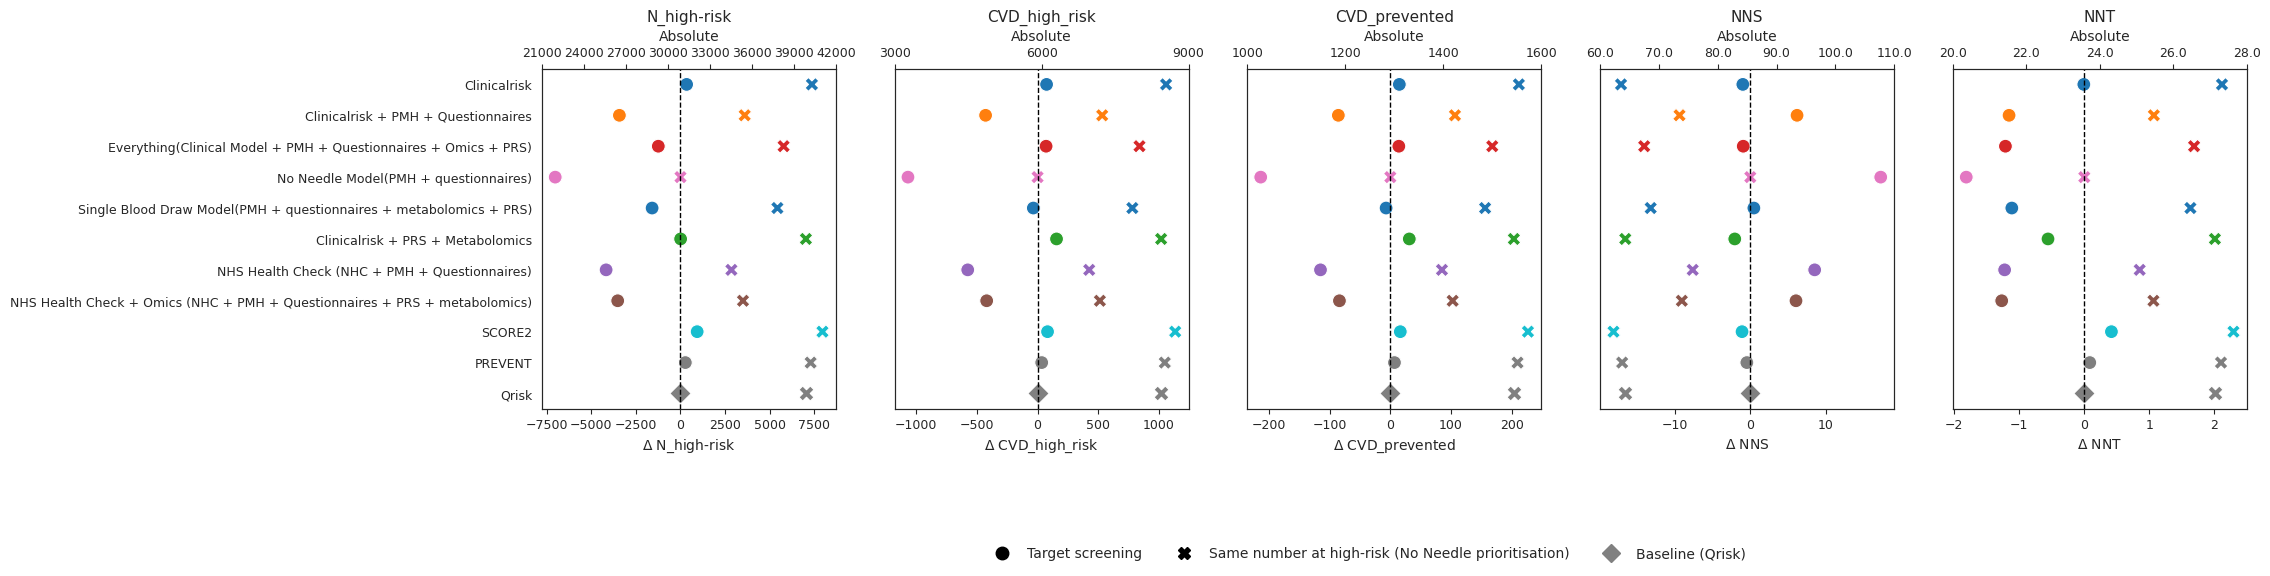

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# Basic settings
baseline_model = "Qrisk"

metrics = ["high_risk", "CVD_high_risk", "CVD_prevented", "NNS", "NNT"]

title_map = {
    "high_risk": "N_high-risk",
    "CVD_high_risk": "CVD_high_risk",
    "CVD_prevented": "CVD_prevented",
    "NNS": "NNS",
    "NNT": "NNT"
}

marker_map = {
    "Threshold": "o",
    "NoNeedle_target": "X"
}

# Baseline data
baseline_row = combined_plot[
    (combined_plot["model"] == baseline_model) &
    (combined_plot["scenario"] == "Threshold")
].iloc[0]

baseline_df = combined_plot[
    (combined_plot["model"] == baseline_model) &
    (combined_plot["scenario"] == "Threshold")
].copy()

for metric in metrics:
    baseline_df[f"{metric}_delta"] = 0

# Split datasets
plot_df = combined_plot[
    ~(
        (combined_plot["model"] == baseline_model) &
        (combined_plot["scenario"] == "Threshold")
    )
].copy()

qrisk_noneedle_df = plot_df[
    (plot_df["model"] == baseline_model) &
    (plot_df["scenario"] == "NoNeedle_target")
].copy()

plot_df_main = plot_df[
    ~(
        (plot_df["model"] == baseline_model) &
        (plot_df["scenario"] == "NoNeedle_target")
    )
].copy()


# Plotting
sns.set_style("white")

fig, axes = plt.subplots(1, len(metrics), figsize=(22, 5))

for i, (ax, metric) in enumerate(zip(axes, metrics)):
    delta_col = f"{metric}_delta"

    # Main coloured points
    sns.scatterplot(
        data=plot_df_main,
        x=delta_col,
        y="model",
        hue="model",
        style="scenario",
        markers=marker_map,
        palette=palette,
        s=100,
        ax=ax,
        legend=False
    )

    # Qrisk + NoNeedle_target (grey X)
    sns.scatterplot(
        data=qrisk_noneedle_df,
        x=delta_col,
        y="model",
        ax=ax,
        color="grey",
        marker="X",
        s=120,
        legend=False
    )

    # Qrisk + Threshold (baseline grey diamond)
    sns.scatterplot(
        data=baseline_df,
        x=delta_col,
        y="model",
        ax=ax,
        color="grey",
        marker="D",
        s=120,
        legend=False
    )

    # Vertical reference line
    ax.axvline(0, color="black", linestyle="--", linewidth=1)

    # Titles
    ax.set_title(title_map[metric], fontsize=11)

    # Bottom axis (delta)
    ax.set_xlabel(r"$\Delta$ " + title_map[metric], fontsize=10)
    ax.set_ylabel("")

    # Top axis (absolute values)
    ax_top = ax.twiny()

    baseline_value = baseline_row[metric]

    xmin, xmax = ax.get_xlim()
    abs_min = xmin + baseline_value
    abs_max = xmax + baseline_value

    step = 2
    abs_range = abs_max - abs_min

    if abs_range > 20: step = 10
    if abs_range > 100: step = 50
    if abs_range > 300: step = 200
    if abs_range > 1000: step = 1000
    if abs_range > 2000: step = 3000

    abs_ticks = np.arange(
        np.floor(abs_min / step) * step,
        np.ceil(abs_max / step) * step + step,
        step
    )

    delta_ticks = abs_ticks - baseline_value

    ax_top.set_xlim(ax.get_xlim())
    ax_top.set_xticks(delta_ticks)

    if metric in ["NNS", "NNT"]:
        ax_top.set_xticklabels([f"{t:.1f}" for t in abs_ticks], fontsize=9)
    else:
        ax_top.set_xticklabels([f"{t:.0f}" for t in abs_ticks], fontsize=9)

    ax_top.set_xlabel("Absolute", fontsize=10)

    # Tick styling
    ax.tick_params(axis="x", labelsize=9)
    ax.tick_params(axis="y", labelsize=9)

    if i != 0:
        ax.set_yticklabels([])
        ax.set_yticks([])

    ax.grid(False)
    ax_top.grid(False)

# Legend (bottom center)
legend_elements = [
    Line2D([0], [0], marker='o', color='w',
           label='Target screening',
           markerfacecolor='black', markeredgecolor='black',
           markersize=9, linestyle='None'),

    Line2D([0], [0], marker='X', color='w',
           label='Same number at high-risk (No Needle prioritisation)',
           markerfacecolor='black', markeredgecolor='black',
           markersize=9, linestyle='None'),

    Line2D([0], [0], marker='D', color='w',
           label='Baseline (Qrisk)',
           markerfacecolor='grey', markeredgecolor='grey',
           markersize=9, linestyle='None')
]

fig.legend(
    handles=legend_elements,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.05),  # move legend below the figure
    ncol=3,                       # horizontal layout
    frameon=False,
    fontsize=10
)

# Adjust layout to make space for legend
plt.subplots_adjust(bottom=0.2)

plt.show()